In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (7, 4)

!pip install -q underthesea

Mounted at /content/drive


Đọc và hợp nhất dữ liệu: Quét và gom toàn bộ các file văn bản thô (sents.txt), nhãn cảm xúc (sentiments.txt) từ các thư mục train, dev, test thành một bảng dữ liệu chuẩn duy nhất. Sử dụng định dạng utf-8-sig để tự động loại bỏ ký tự ẩn BOM nếu có.

Kiểm tra tính toàn vẹn (Validation): Dùng lệnh assert để đảm bảo số lượng câu và số nhãn phải khớp nhau hoàn toàn 100% giữa các file, tránh tình trạng lệch dữ liệu.

Làm sạch và lưu trữ:

Chuẩn hóa Unicode tiếng Việt về dạng dựng sẵn (NFC) để đảm bảo tính đồng nhất khi đếm từ hoặc dùng regex.

Ánh xạ nhãn từ dạng số sang tên gọi trực quan (sentiment_name).

Xuất toàn bộ kết quả thành file chung data_all.csv để phục vụ cho các bước phân tích (EDA) và huấn luyện mô hình tiếp theo.

In [5]:
def read_lines(path):
    with open(path, encoding='utf-8-sig') as f:      # utf-8-sig: tự bỏ BOM nếu có
        return [line.rstrip('\r\n') for line in f]
DATA = '/content/drive/MyDrive/project1_vsfc/data'
paths = sorted(glob.glob(f'{DATA}/**/sents.txt', recursive=True))
print(paths)

rows = []
for p in paths:
    folder = os.path.dirname(p)
    split = os.path.basename(folder)
    texts = read_lines(p)
    sents = read_lines(f'{folder}/sentiments.txt')
    assert len(texts) == len(sents), f'Lệch số dòng ở {folder}'
    print(split, '| nhãn cảm xúc:', sorted(set(sents)))
    rows += [(split, t, int(s)) for t, s in zip(texts, sents)]

df = pd.DataFrame(rows, columns=['split', 'text', 'sentiment'])

# Chuẩn hóa Unicode về dạng NFC (dạng dựng sẵn) để đếm từ, regex, so trùng đều đúng
before = df['text'].copy()
df['text'] = df['text'].apply(lambda s: unicodedata.normalize('NFC', s))
print('Số câu bị đổi sau chuẩn hóa NFC:', (before != df['text']).sum())

print(df.shape)
print(df.groupby('split').size())   # mỗi phần phải xuất hiện đúng 1 lần; nếu tổng ~32.000 là bị đọc trùng thư mục

SENT  = {0: 'negative', 1: 'neutral', 2: 'positive'}
df['sentiment_name'] = df['sentiment'].map(SENT)
df.to_csv(f'{DATA}/data_all.csv', index=False, encoding='utf-8-sig')

['/content/drive/MyDrive/project1_vsfc/data/dev/sents.txt', '/content/drive/MyDrive/project1_vsfc/data/test/sents.txt', '/content/drive/MyDrive/project1_vsfc/data/train/sents.txt']
dev | nhãn cảm xúc: ['0', '1', '2']
test | nhãn cảm xúc: ['0', '1', '2']
train | nhãn cảm xúc: ['0', '1', '2']
Số câu bị đổi sau chuẩn hóa NFC: 0
(16175, 3)
split
dev       1583
test      3166
train    11426
dtype: int64


In [6]:
print(df.isna().sum())
print('Câu rỗng:', (df['text'].str.strip() == '').sum())
print('Câu trùng nội dung:', df.duplicated(subset='text').sum())

# Rò rỉ dữ liệu: câu xuất hiện ở cả hai phần train/dev/test
norm = df['text'].str.lower().str.strip()
sets = {s: set(norm[df['split'] == s]) for s in df['split'].unique()}
for a, b in [('train', 'dev'), ('train', 'test'), ('dev', 'test')]:
    if a in sets and b in sets:
        inter = sets[a] & sets[b]
        print(f'{a} ∩ {b}: {len(inter)} câu trùng '
              f'({len(inter) / len(sets[b]) * 100:.1f}% số câu khác nhau của {b})')

split             0
text              0
sentiment         0
sentiment_name    0
dtype: int64
Câu rỗng: 0
Câu trùng nội dung: 1
train ∩ dev: 0 câu trùng (0.0% số câu khác nhau của dev)
train ∩ test: 0 câu trùng (0.0% số câu khác nhau của test)
dev ∩ test: 0 câu trùng (0.0% số câu khác nhau của test)


sentiment_name
positive    8038
negative    7439
neutral      698
Name: count, dtype: int64
sentiment_name
positive    49.7
negative    46.0
neutral      4.3
Name: count, dtype: float64


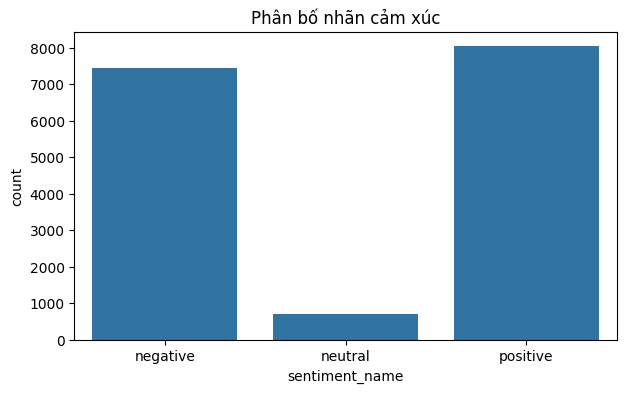

sentiment_name  negative  neutral  positive
split                                      
dev                 44.5      4.6      50.9
test                44.5      5.3      50.2
train               46.6      4.0      49.4


In [8]:
# 4.1 Phân bố nhãn cảm xúc
counts = df['sentiment_name'].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(1))
PROJECT = '/content/drive/MyDrive/project1_vsfc'
sns.countplot(data=df, x='sentiment_name', order=['negative', 'neutral', 'positive'])
plt.title('Phân bố nhãn cảm xúc')
plt.savefig(f'{PROJECT}/results/fig_sentiment_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# 4.2 Tỉ lệ nhãn trong train/dev/test có giống nhau không?
print((pd.crosstab(df['split'], df['sentiment_name'], normalize='index') * 100).round(1))

--- Thống kê tổng quan độ dài câu ---
count    16175.000000
mean        14.229181
std         10.103769
min          2.000000
50%         11.000000
90%         26.000000
95%         33.000000
99%         52.000000
max        161.000000
Name: n_words, dtype: float64


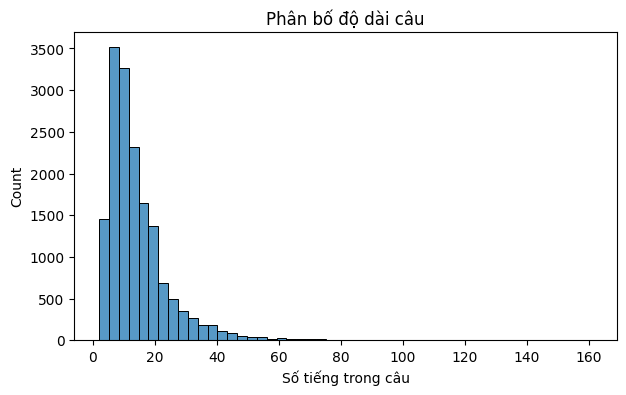

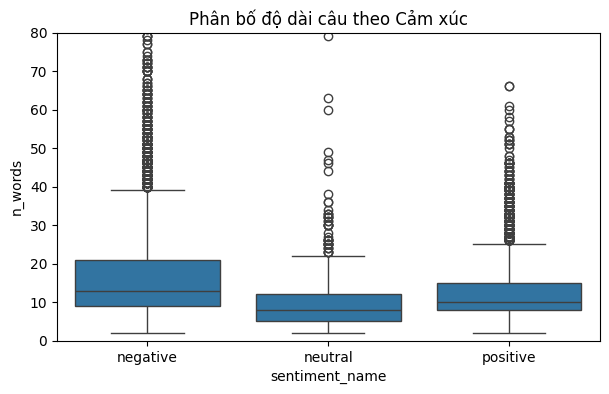

--- Thống kê độ dài theo Cảm xúc ---
                mean  median  max
sentiment_name                   
negative        16.9    13.0  161
neutral          9.8     8.0   79
positive        12.1    10.0   95


In [9]:
# 1. Đếm số tiếng trong câu (theo dấu cách)
df['n_words'] = df['text'].str.split().str.len()
print("--- Thống kê tổng quan độ dài câu ---")
print(df['n_words'].describe(percentiles=[.5, .9, .95, .99]))

# 2. Vẽ và lưu biểu đồ phân bố tổng quan độ dài câu
plt.figure(figsize=(7, 4))
sns.histplot(df['n_words'], bins=50)
plt.xlabel('Số tiếng trong câu')
plt.title('Phân bố độ dài câu')
plt.savefig(f'{PROJECT}/results/fig_length_hist.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Vẽ và lưu biểu đồ boxplot so sánh độ dài câu theo Cảm xúc
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='sentiment_name', y='n_words', order=['negative', 'neutral', 'positive'])
plt.ylim(0, 80)
plt.title('Phân bố độ dài câu theo Cảm xúc')
plt.savefig(f'{PROJECT}/results/fig_length_by_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()

print("--- Thống kê độ dài theo Cảm xúc ---")
print(df.groupby('sentiment_name')['n_words'].agg(['mean', 'median', 'max']).round(1))

In [10]:
from underthesea import word_tokenize
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained('vinai/phobert-base')
sample = df.sample(min(2000, len(df)), random_state=42)
seg = sample['text'].apply(lambda s: word_tokenize(s, format='text'))
lens = seg.apply(lambda s: len(tok.encode(s)))

print(lens.describe(percentiles=[.9, .95, .99]))
for L in [64, 128, 256]:
    print(f'max_length={L}: bị cắt {(lens > L).mean() * 100:.1f}% câu')

# tìm max length

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

count    2000.0000
mean       13.1095
std         7.5292
min         4.0000
50%        11.0000
90%        23.0000
95%        29.0000
99%        39.0100
max        79.0000
Name: text, dtype: float64
max_length=64: bị cắt 0.1% câu
max_length=128: bị cắt 0.0% câu
max_length=256: bị cắt 0.0% câu


In [11]:
from sklearn.feature_extraction.text import CountVectorizer

STOP  = ['là','và','của','có','cho','các','những','một','được','trong','với',
         'này','khi','để','thì','mà','cũng','như','đã','còn','nên','từ','ở',
         'em','mình','ạ','nhé']
TOKEN = r'(?u)\b\w+\b'      # giữ cả từ 1 ký tự như "k", "ạ", "ở"

def top_ngrams(texts, ngram=(1, 1), k=15):
    if ngram == (1, 1):
        cv = CountVectorizer(token_pattern=TOKEN, stop_words=STOP, min_df=3)
    else:
        cv = CountVectorizer(ngram_range=ngram, token_pattern=TOKEN, min_df=3)
    X = cv.fit_transform(texts)
    freq = X.sum(axis=0).A1
    vocab = cv.get_feature_names_out()
    out = []
    for i in freq.argsort()[::-1]:
        if ngram != (1, 1) and any(t in STOP for t in vocab[i].split()):
            continue                      # bỏ cụm có chứa từ dừng
        out.append((vocab[i], int(freq[i])))
        if len(out) == k:
            break
    return out

for lab in ['negative', 'neutral', 'positive']:
    texts = df[df['sentiment_name'] == lab]['text']
    print(f'=== {lab} (từ đơn) ===', top_ngrams(texts))
    print(f'=== {lab} (cụm 2 từ) ===', top_ngrams(texts, ngram=(2, 2)))

=== negative (từ đơn) === [('viên', 3035), ('không', 2579), ('học', 2547), ('giảng', 2039), ('sinh', 2003), ('bài', 1808), ('thầy', 1672), ('nhiều', 1479), ('thực', 1384), ('dạy', 1369), ('hơn', 1190), ('tập', 1150), ('môn', 1129), ('hành', 1060), ('cần', 1053)]
=== negative (cụm 2 từ) === [('sinh viên', 1844), ('thực hành', 1035), ('giảng viên', 944), ('bài tập', 872), ('môn học', 688), ('kiến thức', 455), ('thời gian', 438), ('lý thuyết', 413), ('giảng dạy', 391), ('nội dung', 368), ('khó hiểu', 328), ('tài liệu', 266), ('đồ án', 255), ('nhiều hơn', 233), ('truyền đạt', 233)]
=== neutral (từ đơn) === [('không', 161), ('thầy', 140), ('học', 120), ('viên', 111), ('bài', 96), ('dạy', 77), ('kiến', 74), ('tập', 70), ('giảng', 68), ('sinh', 63), ('thực', 58), ('lớp', 58), ('môn', 53), ('làm', 50), ('ý', 49)]
=== neutral (cụm 2 từ) === [('sinh viên', 57), ('bài tập', 55), ('ý kiến', 43), ('thực hành', 39), ('giảng viên', 31), ('kiến thức', 30), ('môn học', 27), ('giảng dạy', 24), ('giáo vi

In [12]:
# Từ đặc trưng: log của tỉ lệ tần suất (lớp này / các lớp còn lại)
cv = CountVectorizer(min_df=5, token_pattern=TOKEN, stop_words=STOP)
X = cv.fit_transform(df['text'])
vocab = np.array(cv.get_feature_names_out())

def distinctive(col, label, k=15):
    mask = (df[col] == label).values
    a = X[mask].sum(axis=0).A1 + 1      # +1 để tránh chia cho 0
    b = X[~mask].sum(axis=0).A1 + 1
    score = np.log(a / a.sum()) - np.log(b / b.sum())
    idx = score.argsort()[::-1][:k]
    return [(vocab[i], int(a[i] - 1)) for i in idx]

for lab in ['negative', 'neutral', 'positive']:
    print(lab, '→', distinctive('sentiment_name', lab))

negative → [('chiếu', 165), ('mờ', 62), ('hư', 36), ('sài', 33), ('hỏng', 31), ('tệ', 30), ('trùng', 30), ('bụi', 28), ('nghị', 72), ('phòng', 504), ('quạt', 47), ('trễ', 138), ('đoạn', 21), ('muộn', 42), ('hồ', 41)]
neutral → [('tạm', 9), ('cám', 10), ('nàn', 2), ('nhúng', 3), ('ổn', 14), ('cúp', 2), ('nha', 2), ('ơn', 28), ('đặn', 2), ('bình', 10), ('phúc', 1), ('vai', 1), ('tuổi', 1), ('dào', 1), ('dò', 1)]
positive → [('vui', 950), ('gũi', 127), ('hước', 65), ('huyết', 272), ('cởi', 18), ('nhiệt', 2623), ('hòa', 90), ('tận', 1330), ('hoà', 15), ('tình', 3017), ('hăng', 14), ('nhộn', 13), ('thương', 130), ('tân', 12), ('tụy', 36)]


In [13]:
CONTRAST = r'\b(?:nhưng|nhưng mà|tuy nhiên|tuy|mặc dù|dù|bên cạnh đó|chỉ có điều|chỉ tiếc|tuy vậy)\b'
df['has_contrast'] = df['text'].str.lower().str.contains(CONTRAST, regex=True)

print(f"Câu có từ nối đối lập: {df['has_contrast'].mean() * 100:.1f}%")
print((pd.crosstab(df['has_contrast'], df['sentiment_name'], normalize='index') * 100).round(1))

pool = df[df['has_contrast']]
cands = pool.sample(min(50, len(pool)), random_state=42)[['text', 'sentiment_name']].copy()
cands['my_judgement'] = ''     # bạn điền: pos / neg / mixed / neutral
cands.to_csv(f'{PROJECT}/results/mixed_candidates.csv', index=False, encoding='utf-8-sig')

Câu có từ nối đối lập: 4.3%
sentiment_name  negative  neutral  positive
has_contrast                               
False               44.6      4.3      51.1
True                76.0      5.2      18.8


In [14]:
# 8.1 Cùng một câu nhưng nhãn khác nhau
tmp = df.assign(norm=df['text'].str.lower().str.strip())
g = tmp.groupby('norm')['sentiment'].nunique()
conflict = g[g > 1]
print('Câu trùng nhưng nhãn mâu thuẫn:', len(conflict))
for norm_text in conflict.index[:5]:
    print(' •', norm_text, '→', sorted(tmp.loc[tmp['norm'] == norm_text, 'sentiment_name'].unique()))

# 8.2 Câu quá ngắn (cần chạy Bước 5a trước để có cột n_words)
short = df[df['n_words'] <= 3]
print('Câu <= 3 tiếng:', len(short))
if len(short):
    print(short[['text', 'sentiment_name']].sample(min(10, len(short)), random_state=1))

# 8.3 Chữ số, link
print('Có chữ số: %.1f%%' % (df['text'].str.contains(r'\d').mean() * 100))
print('Có link:   %.1f%%' % (df['text'].str.contains(r'http|www').mean() * 100))

Câu trùng nhưng nhãn mâu thuẫn: 1
 • thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian . → ['negative', 'positive']
Câu <= 3 tiếng: 217
                text sentiment_name
4954         không !        neutral
2058       đi muộn .       negative
2183        tất cả .        neutral
3975       cô xinh .       positive
6059      dạy chậm .       negative
5960        đầy đủ .        neutral
7848   nhiệt huyết .       positive
14030      dễ hiểu .       positive
5505          nope .        neutral
296           good .       positive
Có chữ số: 4.7%
Có link:   0.0%


In [15]:
from collections import Counter
import pandas as pd

path = "/content/drive/MyDrive/project1_vsfc/data/data_all.csv"
df = pd.read_csv(path)

tok = Counter(w for s in df["text"].astype(str) for w in s.split())
abbr = ["k","ko","dc","đc","dk","sv","gv","j","vs","hok","ok","vd","mn","trc","cx","wa"]
print({a: tok[a] for a in abbr if tok[a]})

special = ["colonsmile","colonsad","colonsurprise","colonlove","colonsmilesmile",
           "coloncontemn","colonbigsmile","coloncc","colonsmallsmile","coloncolon",
           "colonlovelove","colonhihi","doubledot","colonsadcolon",
           "colondoublesurprise","vdotv","dotdotdot","fraction","cshrap"]
print({t: tok[t] for t in special})

{'ko': 1, 'đc': 3, 'ok': 20, 'trc': 1}
{'colonsmile': 39, 'colonsad': 13, 'colonsurprise': 2, 'colonlove': 13, 'colonsmilesmile': 18, 'coloncontemn': 11, 'colonbigsmile': 7, 'coloncc': 1, 'colonsmallsmile': 6, 'coloncolon': 1, 'colonlovelove': 1, 'colonhihi': 7, 'doubledot': 123, 'colonsadcolon': 3, 'colondoublesurprise': 4, 'vdotv': 12, 'dotdotdot': 6, 'fraction': 33, 'cshrap': 0}
